# Capability sweeps

**A forecaster that does well on your data today can fall apart when the history gets shorter or the data gets noisier, and one score never tells you which.**

Every simple forecaster is a bet on the kind of series it will meet. The last value bets that the series wanders (a random walk). The average of the history bets that it sits around a fixed level. A straight line bets on a steady trend. In this notebook we score three such bets on the scenario grid, check that a bad score means a weak model and not a broken one, and then sweep the length of the history and the amount of noise to find where each bet stops paying.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from timegym import PATTERNS, Forecast, NaiveForecaster, Pipeline

## Three bets

Two of the bets are built in (`NaiveForecaster` with `strategy="last"` or `"mean"`). The straight line is our own model: two methods, `fit` and `predict`, as in [Write and test a custom model](02_custom_model.ipynb). It fits a least-squares line through the whole history and extends it. Passing the class lets the pipeline make a fresh, unfitted line for every series.

In [2]:
class StraightLine:
    def fit(self, context):                 # history: one row per past step
        self.names_ = tuple(context.columns)
        self.origin_ = float(context.index[0])
        times = context.index.to_numpy(dtype=float) - self.origin_
        design = np.column_stack([np.ones(len(times)), times])
        self.coefficients_ = np.linalg.lstsq(design, context.to_numpy(dtype=float), rcond=None)[0]
        return self

    def predict(self, future_index):        # the dates to forecast
        times = future_index.to_numpy(dtype=float) - self.origin_
        design = np.column_stack([np.ones(len(times)), times])
        return Forecast(index=future_index, point=design @ self.coefficients_, target_names=self.names_)


models = {
    "Last value": Pipeline(NaiveForecaster(strategy="last")),
    "Average of the history": Pipeline(NaiveForecaster(strategy="mean")),
    "Straight line": Pipeline(StraightLine),
}

## Each bet has a home

Score all three on the full grid: ten kinds of series, each at a low and a high noise level, ten draws per cell. Here are the scores at low noise, where the bets differ most:

In [3]:
cards = {name: model.scorecard() for name, model in models.items()}
low_noise = pd.DataFrame({
    name: card.table.query("noise == 'Low noise'").set_index("title")["score"]
    for name, card in cards.items()
}).round().astype(int)
low_noise.loc["Overall (both noise levels)"] = [round(card.score) for card in cards.values()]
low_noise

,Last value,Average of the history,Straight line
title,,,
Pure noise,56,99,96
Noise around a fixed level,56,99,96
Straight-line trend,10,0,96
Repeating seasonal cycle,3,5,5
Trend + seasonal cycle,2,0,5
Sudden level shift,70,1,41
Mean reversion (AR(1)): shocks fade,78,93,76
Irregular cycles (AR(2)),35,66,63
Random walk: shocks never fade,99,33,47


Each bet nails its own home row and pays for it elsewhere. The last value scores 99 on the random walk, the average 99 on noise around a fixed level, and the straight line 96 on the trend. Away from home the same bets collapse: the average scores 0 on the trend, because the trend has moved on from the average of its past, and the straight line scores 47 on the random walk, because it extends a slope that the wandering happened to trace. The straight line has the best overall score (66), but that is a fact about this grid's mix of rows, not about forecasting in general: on a random walk it loses badly to the one-line last value. None of the three can follow a repeating cycle.

## A bad score, or a broken model?

The average of the history fails the trend completely. Did it break? Look at the checks TimeGym ran on one of those forecasts:

In [4]:
average = cards["Average of the history"]
trend_cell = next(index for index, cell in enumerate(average.cells) if cell.pattern == "trend")   # low noise comes first
trend_case = next(entry for entry in average.run.cases if entry.scenario_index == trend_cell)
pd.set_option("display.max_colwidth", None)
checks = pd.DataFrame([{"check": item.name, "status": item.status, "what it says": item.message}
                       for item in trend_case.result.diagnostics])
assert checks.set_index("check").loc["forecast_contract", "status"] == "PASS"         # the output is well formed
assert checks.set_index("check").loc["point_accuracy", "status"] == "INCONCLUSIVE"    # the error is scored, not judged
checks

,check,status,what it says
0,forecast_contract,PASS,"Forecast indices, target order, shapes, finiteness, and quantile order satisfy the declared contract."
1,point_accuracy,INCONCLUSIVE,Point scores are descriptive; no capability acceptance tolerance was declared.
2,quantile_accuracy,UNSUPPORTED,No explicit quantile forecasts were supplied.
3,sample_scores,UNSUPPORTED,No joint predictive samples were supplied.


The output checks (`forecast_contract`) pass: right dates, right shape, no missing values. The accuracy check (`point_accuracy`) is INCONCLUSIVE, which means scored, but with no pass mark set: TimeGym won't invent a threshold for how good is good enough. So a red cell on the scorecard is a weak model, not a broken one. A broken one fails its output checks, and that is what fails a build ([Faults, repairs and replay](03_faults_repairs_and_replay.ipynb) shows how).

## How much history does each bet need?

The grid gives every model 120 steps of history. Sweep that from 24 to 480 steps on two rows, the trend and the random walk, at low noise. Each point is a scorecard cell with 20 draws (`context_length` sets the history, `patterns` picks the rows):

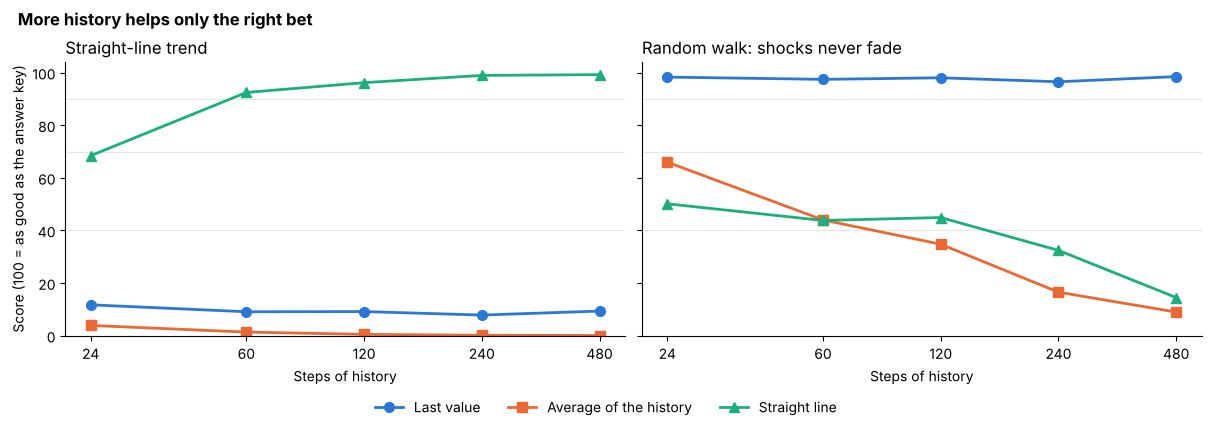

In [5]:
COLORS = {"Last value": "#2a78d6", "Average of the history": "#eb6834", "Straight line": "#1baf7a"}
MARKERS = {"Last value": "o", "Average of the history": "s", "Straight line": "^"}
ROWS = ["trend", "random_walk"]


def sweep(**settings):
    # Score every model on the two rows; one table row per model, pattern and noise level.
    return pd.concat([model.scorecard(ROWS, instances=20, **settings).table.assign(model=name)
                      for name, model in models.items()], ignore_index=True)


def plot_sweep(scores, x, xlabel, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True, layout="constrained")
    ticks = sorted(scores[x].unique())
    for ax, pattern in zip(axes, ROWS):
        for band in (40, 70, 90):   # where the verdicts change: Struggles, Good, Nails it
            ax.axhline(band, color="0.9", linewidth=0.8, zorder=0)
        for name in models:
            line = scores[(scores["pattern"] == pattern) & (scores["model"] == name)].sort_values(x)
            ax.plot(line[x], line["score"], color=COLORS[name], marker=MARKERS[name],
                    linewidth=2, markersize=7, label=name)
        ax.set_xscale("log")
        ax.set_xticks(ticks, [f"{tick:g}" for tick in ticks])
        ax.minorticks_off()
        ax.set(xlabel=xlabel, ylim=(0, 104))
        ax.set_title(PATTERNS[pattern].title, loc="left")
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].set_ylabel("Score (100 = as good as the answer key)")
    fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=3, frameon=False)
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    plt.show()


by_history = pd.concat([sweep(noise_levels=[0.5], context_length=steps).assign(history=steps)
                        for steps in (24, 60, 120, 240, 480)], ignore_index=True)
plot_sweep(by_history, "history", "Steps of history", "More history helps only the right bet")

In [6]:
history_table = by_history.pivot_table(index=["pattern", "history"], columns="model", values="score").round().astype(int)
assert history_table.loc[("trend", 480), "Straight line"] > history_table.loc[("trend", 24), "Straight line"]   # the line needs history
assert history_table.loc[("random_walk", 480), "Average of the history"] < history_table.loc[("random_walk", 24), "Average of the history"]   # a wrong bet gets worse
history_table

model                Average of the history  Last value  Straight line
pattern     history                                                   
random_walk 24                           66          98             50
            60                           44          97             44
            120                          35          98             45
            240                          17          97             32
            480                           9          98             14
trend       24                            4          12             68
            60                            1           9             92
            120                           0           9             96
            240                           0           8             99
            480                           0           9             99

On the trend, the straight line needs some history: from 24 steps it scores 68, from 60 already 92. The average gets no help, because however much history it sees, the trend has moved on. On the random walk, more history makes both wrong bets worse: the average falls from 66 to 9 and the straight line from 50 to 14, because older history lies further from where the walk is now. The last value doesn't care how much history it gets. More data only helps a model whose bet is right.

## How much noise can each bet take?

Now hold the history at 120 steps and sweep the noise, from a standard deviation of 0.25 to 4 (`noise_levels` takes a list):

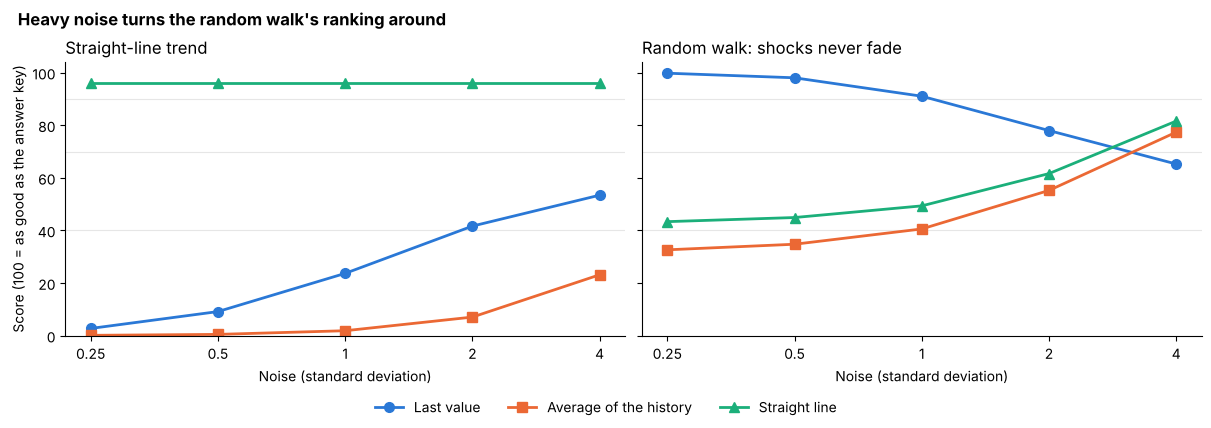

In [7]:
by_noise = sweep(noise_levels=[0.25, 0.5, 1.0, 2.0, 4.0])
plot_sweep(by_noise, "noise_sd", "Noise (standard deviation)", "Heavy noise turns the random walk's ranking around")

In [8]:
noise_table = by_noise.pivot_table(index=["pattern", "noise_sd"], columns="model", values="score").round().astype(int)
quiet, loud = noise_table.loc[("random_walk", 0.25)], noise_table.loc[("random_walk", 4.0)]
assert quiet["Last value"] > max(quiet["Average of the history"], quiet["Straight line"])   # quiet walk: copy the last value
assert loud["Last value"] < min(loud["Average of the history"], loud["Straight line"])      # noisy walk: copying overreacts
noise_table

model                 Average of the history  Last value  Straight line
pattern     noise_sd                                                   
random_walk 0.25                          33         100             43
            0.50                          35          98             45
            1.00                          41          91             49
            2.00                          55          78             62
            4.00                          77          65             82
trend       0.25                           0           3             96
            0.50                           0           9             96
            1.00                           2          24             96
            2.00                           7          42             96
            4.00                          23          53             96

On the random walk the ranking turns around. With little noise the last value scores 100, the straight line 43 and the average 33. With heavy noise the straight line (82) and the average (77) beat the last value (65). When every observation carries a lot of noise, the last one is a poor reading of where the walk is, and the answer key smooths over many recent values instead; copying one noisy value overreacts.

On the trend, the straight line holds at 96 whatever the noise, while the last value climbs from 3 to 53. It didn't get better: the score compares the avoidable error with the noise nobody can predict, so the same flat-line mistake counts for less when the noise is large. Read a rising score in a noise sweep as "the mistake matters less", not "the model learned something".

**What this doesn't show.** Each sweep changes one setting and holds the rest (24 steps ahead, the grid's default series), so it says nothing about combinations such as short and noisy. With 20 draws per point, scores move by a few points with the seed: read the shape of the curves, not the decimals. And these are point forecasts only; uncertainty has its own tutorials.

## Change one thing

- Sweep how far ahead the models forecast with `horizon=` (for example 6, 24 and 96 steps).
- Add the Ridge pipeline from the [Quick start](01_quick_start.ipynb) as a fourth bet: where does a learned model sit between them?
- Swap the two rows for `"seasonal"` and `"level_shift"`: which bet copes with a sudden jump as the history grows?

**Next:** [Composed and financial stresses](11_composed_and_financial_stresses.ipynb).